In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, classification_report, mean_squared_error
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

%matplotlib inline

#### Summary

Loads the data science, visualization, preprocessing, regression, and boosting libraries used throughout the notebook.


In [3]:
df = pd.read_csv('health_insurance.csv')

#### Summary

Reads the health insurance CSV into `df` as the working dataset.


In [4]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


#### Summary

Previews the first five records to confirm the dataset columns and example values.


In [5]:
df.tail()

,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.5483
1334,18,female,31.92,0,no,northeast,2205.9808
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603


#### Summary

Previews the final five records to inspect the end of the dataset.


In [6]:
df.sample(5)

,age,sex,bmi,children,smoker,region,charges
489,53,male,31.16,1,no,northwest,10461.9794
160,42,female,26.60,0,yes,northwest,21348.7060
212,24,male,28.50,2,no,northwest,3537.7030
278,59,male,31.79,2,no,southeast,12928.7911
907,44,female,32.34,1,no,southeast,7633.7206


#### Summary

Displays a random sample of five records for a quick check of varied observations.


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


#### Summary

Reports column data types, non-null counts, and memory usage; the dataset has 1,338 observations and seven columns.


In [8]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


#### Summary

Summarizes numeric columns with descriptive statistics such as mean, quartiles, and range.


In [9]:
df.duplicated().sum()

np.int64(1)

#### Summary

Counts exact duplicate records before cleaning; one duplicate is present.


In [10]:
df = df.drop_duplicates()

#### Summary

Removes exact duplicate records so repeated rows do not influence modeling.


In [11]:
df.duplicated().sum()

np.int64(0)

#### Summary

Checks duplicates again after cleaning; no duplicate rows remain.


In [12]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

#### Summary

Counts missing values per column; the dataset contains no missing values.


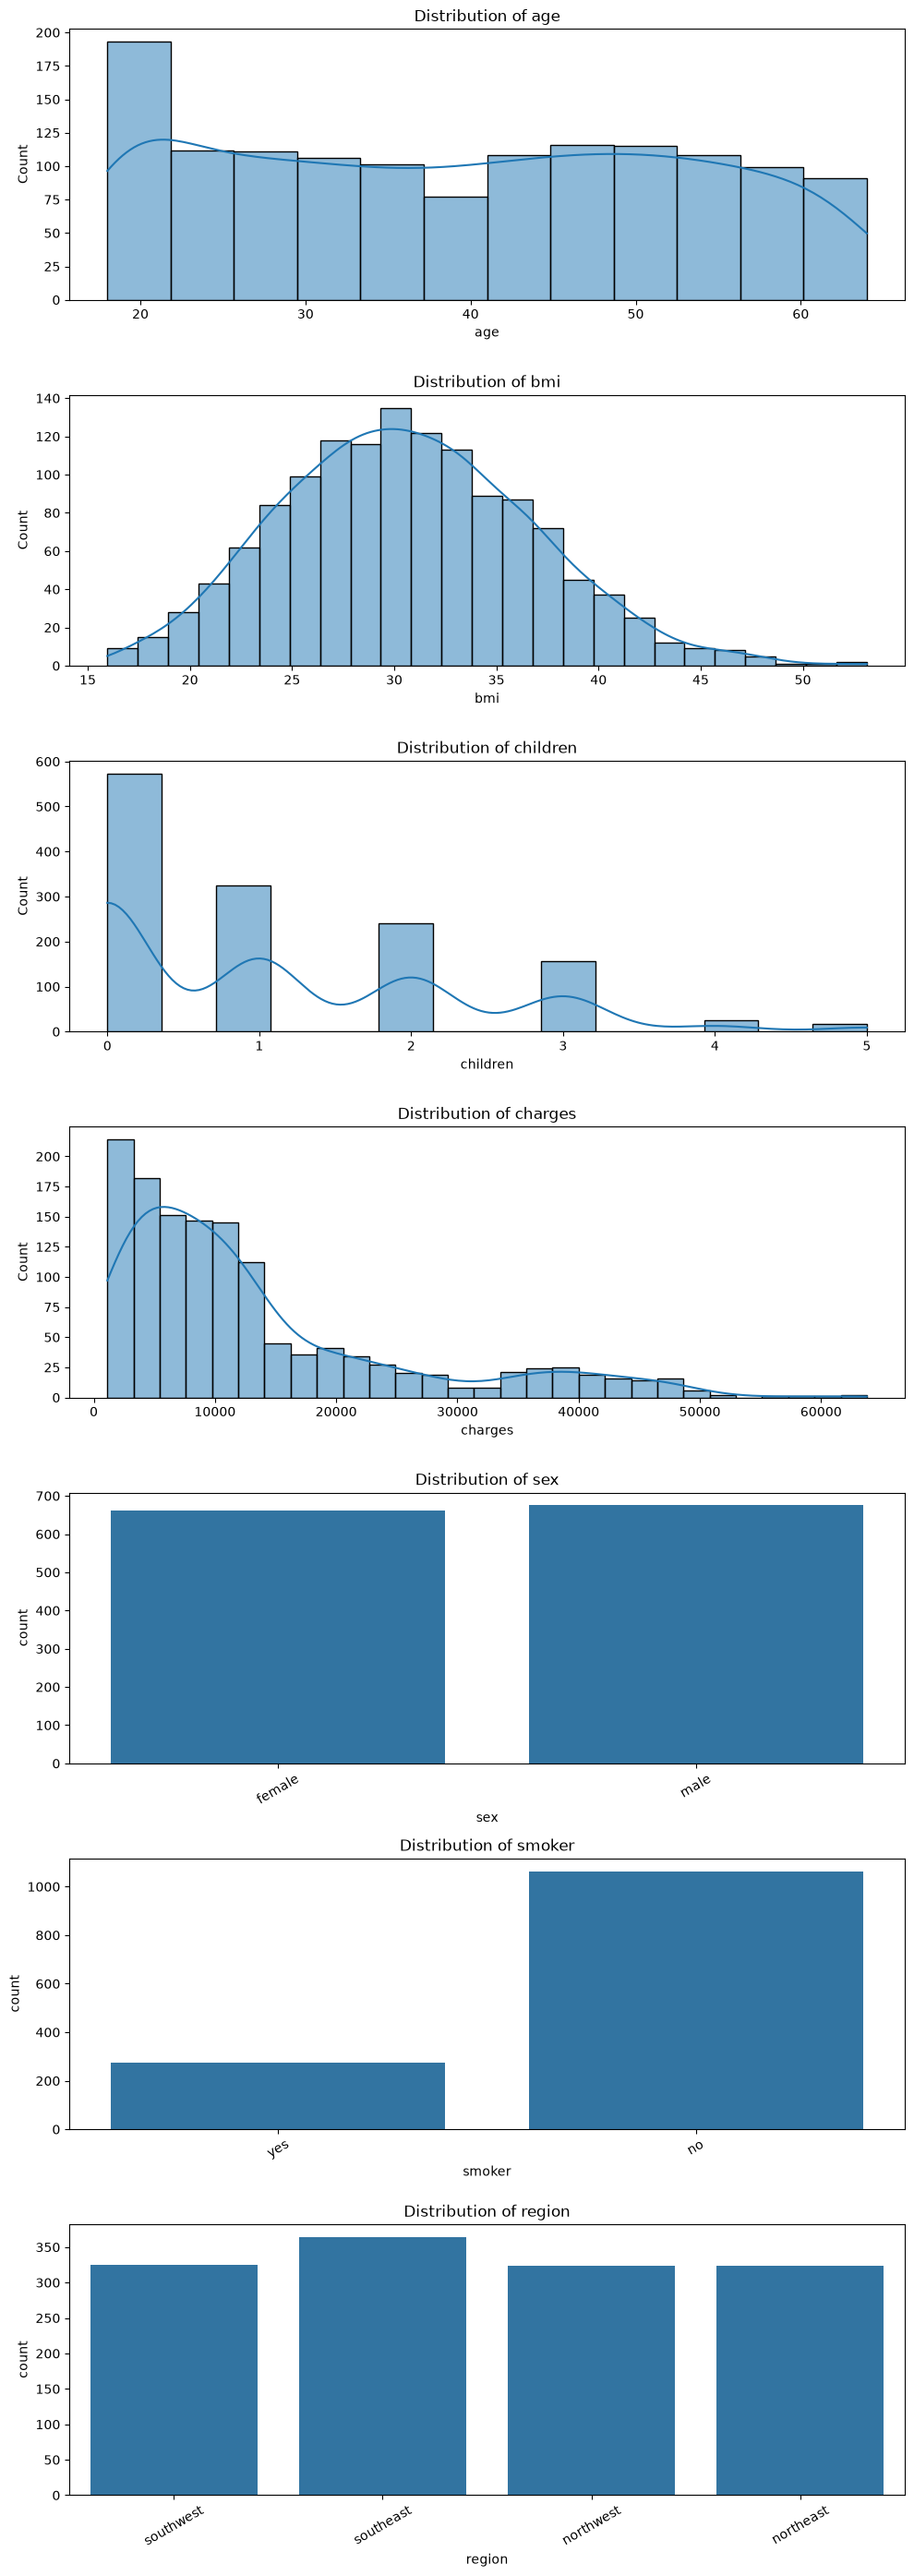

In [13]:
numeric_cols = df.select_dtypes(include="number").columns
categorical_cols = df.select_dtypes(exclude="number").columns

fig, axes = plt.subplots(
    len(numeric_cols) + len(categorical_cols), 1,
    figsize=(10, 4 * (len(numeric_cols) + len(categorical_cols)))
)

for ax, col in zip(axes, numeric_cols):
    sns.histplot(data=df, x=col, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")

for ax, col in zip(axes[len(numeric_cols):], categorical_cols):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

#### Summary

Plots numeric-variable distributions and categorical-value counts to support exploratory analysis.


Correlation with charges:


charges             1.000000
smoker_yes          0.787234
age                 0.298308
bmi                 0.198401
region_southeast    0.073578
children            0.067389
sex_male            0.058044
region_northwest   -0.038695
region_southwest   -0.043637
Name: charges, dtype: float64

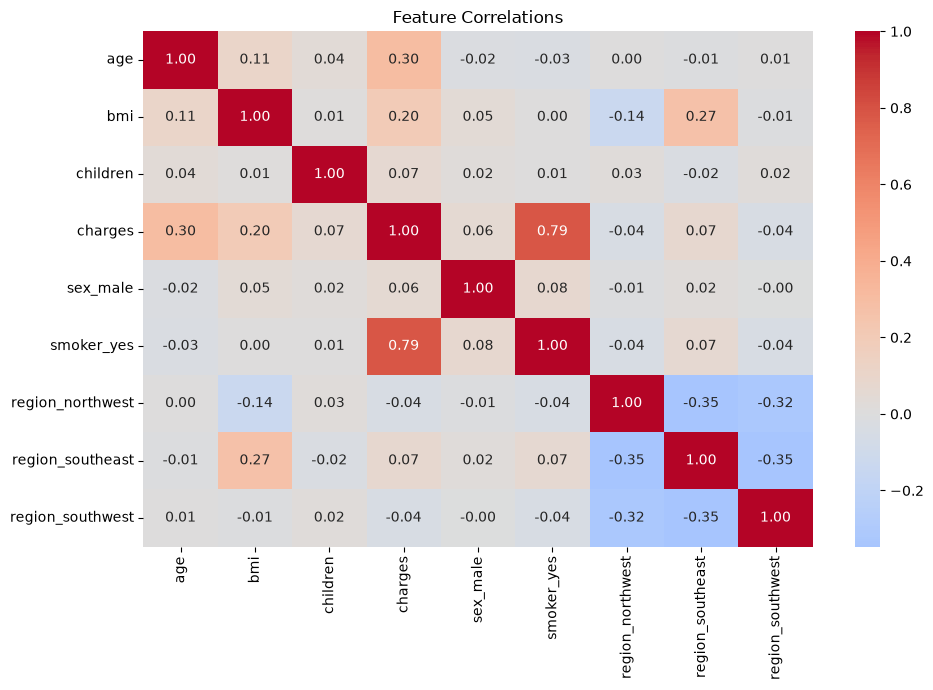

In [14]:
corr_df = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

corr_matrix = corr_df.corr(numeric_only=True)

print("Correlation with charges:")
display(corr_matrix["charges"].sort_values(ascending=False))

plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Feature Correlations")
plt.tight_layout()
plt.show()

#### Summary

One-hot encodes categorical variables for correlation analysis and displays correlations with insurance charges; these are associations, not causal effects.


,count,mean,std,min,25%,50%,75%,max
age,1337.0,39.222139,14.044333,18.0000,27.000,39.0000,51.00000,64.00000
bmi,1337.0,30.663452,6.100468,15.9600,26.290,30.4000,34.70000,53.13000
children,1337.0,1.095737,1.205571,0.0000,0.000,1.0000,2.00000,5.00000
charges,1337.0,13279.121487,12110.359656,1121.8739,4746.344,9386.1613,16657.71745,63770.42801


,skewness
age,0.054781
bmi,0.283914
children,0.937421
charges,1.515391


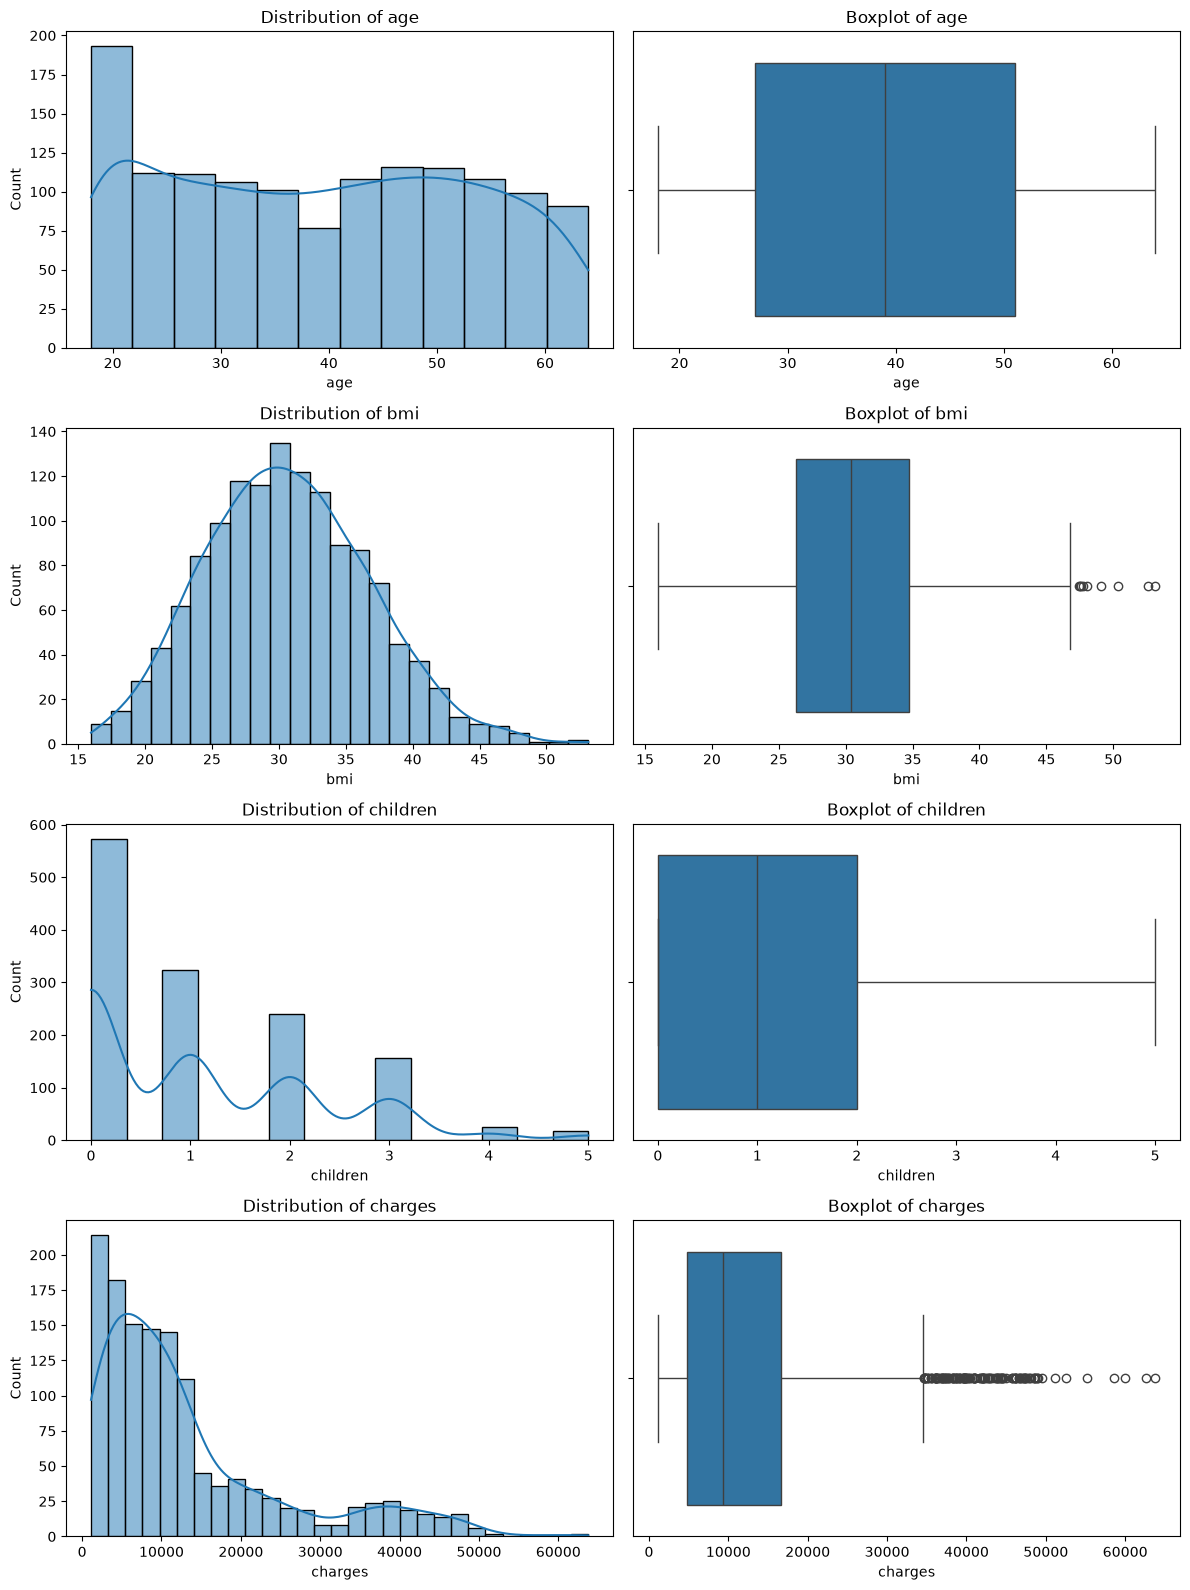


sex distribution:


,percent
sex,
male,50.486163
female,49.513837



smoker distribution:


,percent
smoker,
no,79.506358
yes,20.493642



region distribution:


,percent
region,
southeast,27.225131
southwest,24.308153
northwest,24.233358
northeast,24.233358


In [15]:
display(df[numeric_cols].describe().T)
display(df[numeric_cols].skew().rename("skewness").to_frame())

fig, axes = plt.subplots(len(numeric_cols), 2, figsize=(12, 4 * len(numeric_cols)))

for i, col in enumerate(numeric_cols):
    sns.histplot(data=df, x=col, kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f"Distribution of {col}")

    sns.boxplot(data=df, x=col, ax=axes[i, 1])
    axes[i, 1].set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

for col in categorical_cols:
    print(f"\n{col} distribution:")
    display(df[col].value_counts(normalize=True).mul(100).rename("percent").to_frame())

#### Summary

Displays numeric summaries and skewness, then plots distributions and boxplots; insurance charges are strongly right-skewed.


In [16]:
print(f"Dataset: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Duplicate rows: {df.duplicated().sum()}")
print("\nMissing values:")
display(df.isna().sum().rename("missing").to_frame())

print("\nNumeric columns:")
display(df.describe().T)

print("\nCategorical columns:")
for column in categorical_cols:
    print(f"\n{column} ({df[column].nunique()} categories):")
    display(df[column].value_counts().to_frame("count"))

print("\nCharges by smoker status:")
display(df.groupby("smoker")["charges"].agg(["count", "mean", "median"]).round(2))

Dataset: 1,337 rows × 7 columns
Duplicate rows: 0

Missing values:


,missing
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0



Numeric columns:


,count,mean,std,min,25%,50%,75%,max
age,1337.0,39.222139,14.044333,18.0000,27.000,39.0000,51.00000,64.00000
bmi,1337.0,30.663452,6.100468,15.9600,26.290,30.4000,34.70000,53.13000
children,1337.0,1.095737,1.205571,0.0000,0.000,1.0000,2.00000,5.00000
charges,1337.0,13279.121487,12110.359656,1121.8739,4746.344,9386.1613,16657.71745,63770.42801



Categorical columns:

sex (2 categories):


,count
sex,
male,675
female,662


... (2 outputs left out)


region (4 categories):


,count
region,
southeast,364
southwest,325
northwest,324
northeast,324



Charges by smoker status:


,count,mean,median
smoker,,,
no,1063,8440.66,7345.73
yes,274,32050.23,34456.35


#### Summary

Collects a compact data-quality and EDA overview, including shape, missing values, numeric statistics, and category frequencies.


,lower_bound,upper_bound,outlier_count
column,,,
age,-9.000000,87.000000,0
bmi,13.675000,47.315000,9
children,-3.000000,5.000000,0
charges,-13120.716175,34524.777625,139


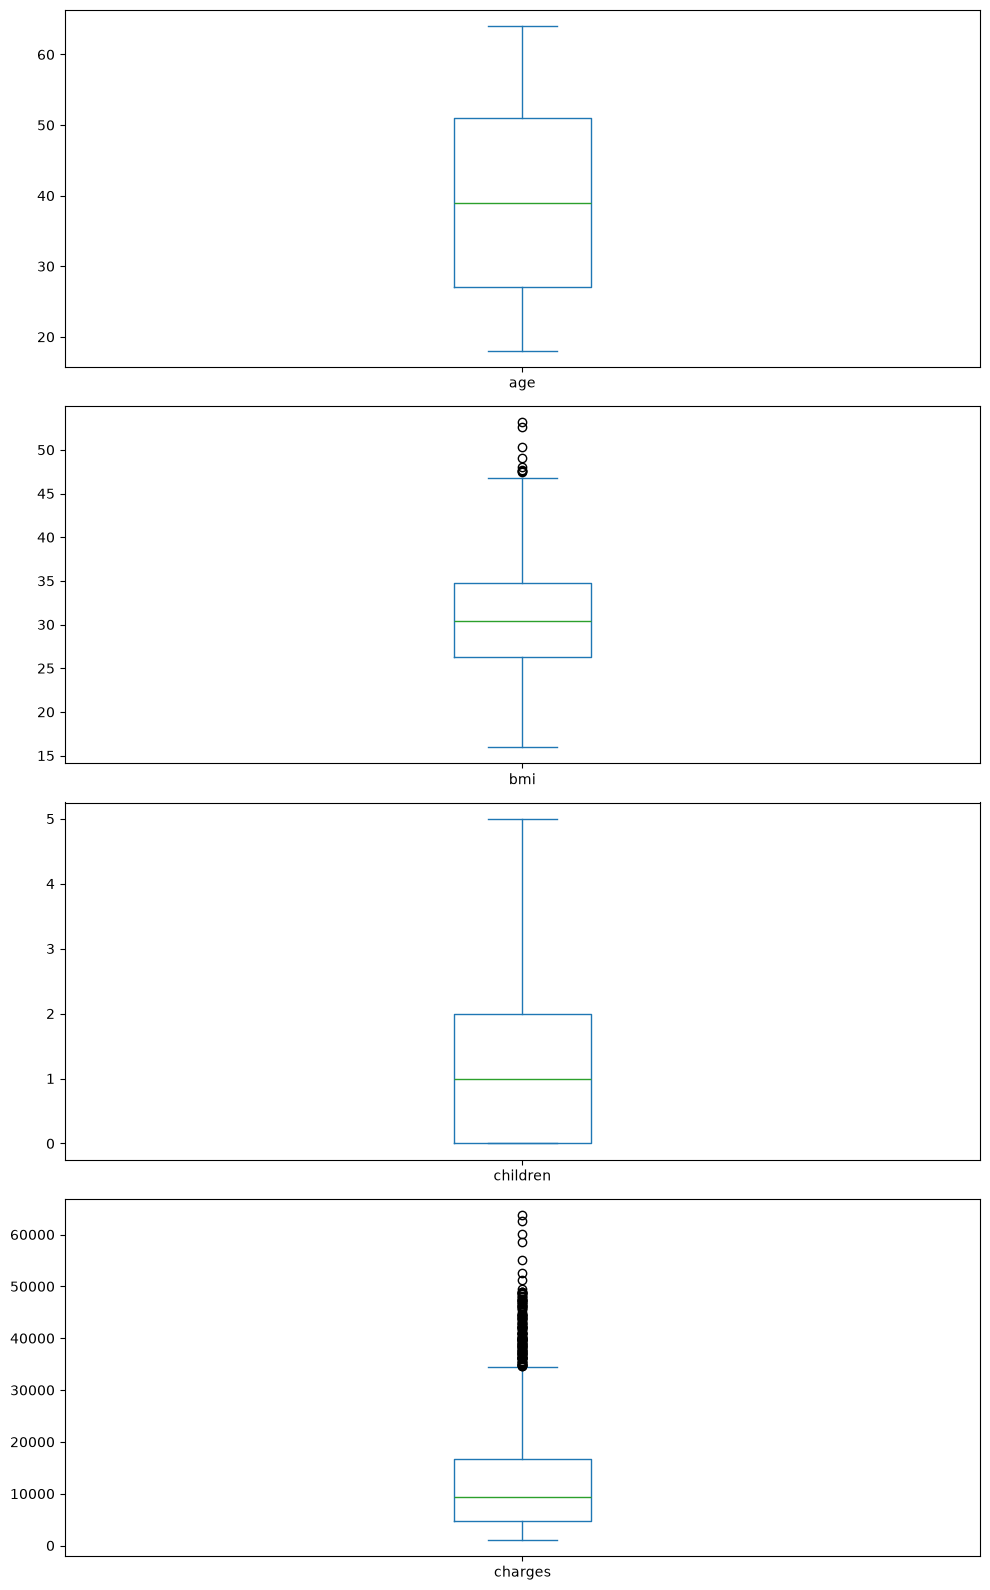

In [17]:
outlier_rows = []

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    count = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()

    outlier_rows.append({
        "column": col,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": count
    })

outlier_summary = pd.DataFrame(outlier_rows).set_index("column")
display(outlier_summary)

df[numeric_cols].plot(
    kind="box",
    subplots=True,
    layout=(len(numeric_cols), 1),
    figsize=(10, 4 * len(numeric_cols)),
    sharex=False
)
plt.tight_layout()
plt.show()

#### Summary

Uses the 1.5?IQR rule to count potential outliers in numeric columns; flagged observations should be investigated rather than automatically removed.


In [19]:
df_encoded = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

display(df_encoded.head())

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


#### Summary

One-hot encodes categorical predictors to create an encoded dataset for inspection.


In [20]:
X = df.drop(columns="charges")
y = df["charges"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

numeric_features = X.select_dtypes(include="number").columns
categorical_features = X.select_dtypes(exclude="number").columns

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

print("Training features:", X_train_scaled.shape)
print("Test features:", X_test_scaled.shape)

#### Summary

Separates charges from predictors, creates a reproducible 80/20 train-test split, and fits scaling/one-hot preprocessing on training features only.


In [21]:
feature_skewness = X_train[numeric_features].skew().sort_values(ascending=False)
target_skewness = y_train.skew()

display(feature_skewness.rename("skewness").to_frame())
print(f"Training target (charges) skewness: {target_skewness:.2f}")

# A log1p transform is useful for a strongly right-skewed, nonnegative target.
if target_skewness > 1 and (y_train >= 0).all() and (y_test >= 0).all():
    y_train_log = np.log1p(y_train)
    y_test_log = np.log1p(y_test)
    print(f"Applied log1p to charges. Transformed training skewness: {y_train_log.skew():.2f}")
else:
    y_train_log = y_train.copy()
    y_test_log = y_test.copy()
    print("No target transformation applied.")

,skewness
children,0.952955
bmi,0.318271
age,0.066010


#### Summary

Measures training-set feature and target skewness; because charges are nonnegative and strongly right-skewed, applies `log1p` to the target.


In [23]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

from sklearn.ensemble import (
    GradientBoostingRegressor,
    ExtraTreesRegressor,
    AdaBoostRegressor,
    VotingRegressor
)

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "SVR": SVR(kernel="rbf"),
    "KNN": KNeighborsRegressor(n_neighbors=5),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "XGBoost": XGBRegressor(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ),
    "CatBoost": CatBoostRegressor(
        iterations=500,
        learning_rate=0.03,
        depth=6,
        loss_function="RMSE",
        random_seed=42,
        verbose=False,
        thread_count=-1
    ),
    "Extra Trees": ExtraTreesRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "AdaBoost": AdaBoostRegressor(n_estimators=100, random_state=42),
    "Voting Ensemble": VotingRegressor(estimators=[
        ("linear", LinearRegression()),
        ("random_forest", RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)),
        ("gradient_boosting", GradientBoostingRegressor(random_state=42))
    ])
}

results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train_log)
    y_pred = np.maximum(0, np.expm1(model.predict(X_test_scaled)))
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "MAE": np.mean(np.abs(y_test - y_pred)),
        "RMSE": np.sqrt(np.mean((y_test - y_pred) ** 2)),
        "R?": 1 - np.sum((y_test - y_pred) ** 2) / np.sum((y_test - y_test.mean()) ** 2)
    })

results_df = pd.DataFrame(results).set_index("Model").sort_values("RMSE")
display(results_df.round(2))

,MAE,RMSE,R?
Model,,,
Gradient Boosting,2091.50,4341.54,0.90
Random Forest,2051.38,4371.76,0.90
Voting Ensemble,2305.98,4525.85,0.89
CatBoost,2314.02,4635.82,0.88
AdaBoost,3343.79,4671.41,0.88
XGBoost,2391.29,4715.45,0.88
Extra Trees,2310.13,4979.63,0.87
SVR,2349.44,5062.71,0.86
Decision Tree,2897.25,6188.55,0.79


#### Summary

Fits baseline regressors, including Linear Regression, Decision Tree, Random Forest, Gradient Boosting, XGBoost, and CatBoost, then ranks them by held-out RMSE.


,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R²,Test R²,RMSE gap (test - train)
Model,,,,,,,
Gradient Boosting,1842.69,2091.50,4133.37,4341.54,0.88,0.90,208.17
Random Forest,954.48,2051.38,2325.81,4371.76,0.96,0.90,2045.95
Voting Ensemble,2205.83,2305.98,4462.66,4525.85,0.85,0.89,63.20
CatBoost,1811.35,2314.02,4011.44,4635.82,0.88,0.88,624.38
AdaBoost,3328.21,3343.79,4700.33,4671.41,0.84,0.88,-28.92
XGBoost,1895.05,2391.29,4148.74,4715.45,0.87,0.88,566.71
Extra Trees,0.00,2310.13,0.00,4979.63,1.00,0.87,4979.63
SVR,2195.85,2349.44,4746.39,5062.71,0.84,0.86,316.32
Decision Tree,0.00,2897.25,0.00,6188.55,1.00,0.79,6188.55


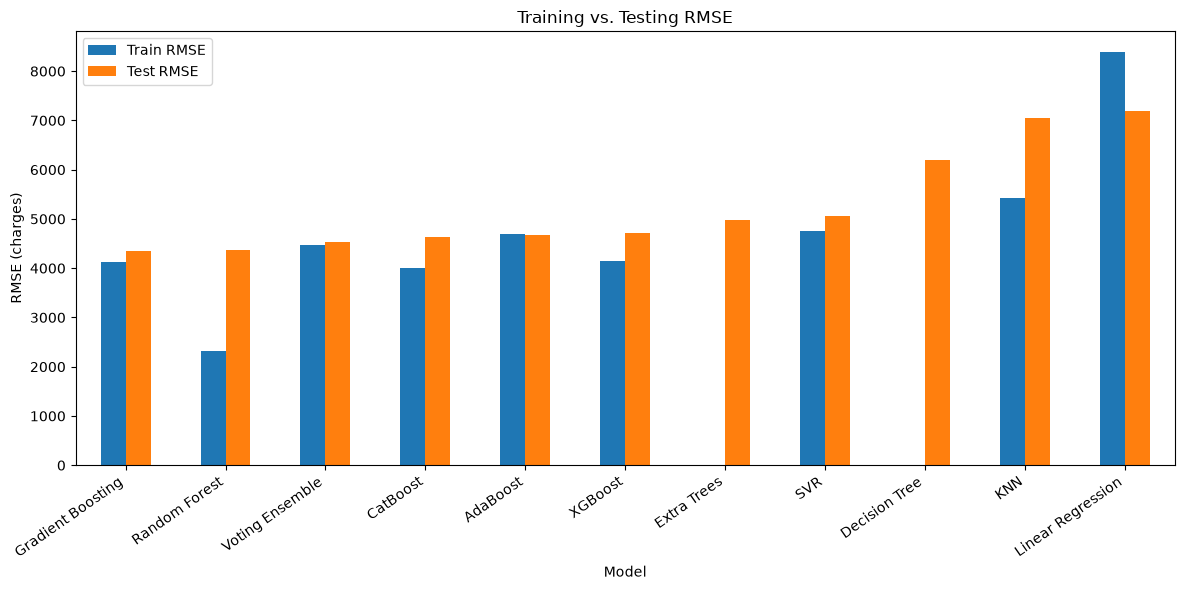

In [24]:
evaluation_rows = []

for model_name, fitted_model in models.items():
    train_pred = np.maximum(0, np.expm1(fitted_model.predict(X_train_scaled)))
    test_pred = predictions[model_name]

    train_mae = np.mean(np.abs(y_train - train_pred))
    test_mae = np.mean(np.abs(y_test - test_pred))

    train_rmse = np.sqrt(np.mean((y_train - train_pred) ** 2))
    test_rmse = np.sqrt(np.mean((y_test - test_pred) ** 2))

    train_r2 = 1 - np.sum((y_train - train_pred) ** 2) / np.sum((y_train - y_train.mean()) ** 2)
    test_r2 = 1 - np.sum((y_test - test_pred) ** 2) / np.sum((y_test - y_test.mean()) ** 2)

    evaluation_rows.append({
        "Model": model_name,
        "Train MAE": train_mae,
        "Test MAE": test_mae,
        "Train RMSE": train_rmse,
        "Test RMSE": test_rmse,
        "Train R²": train_r2,
        "Test R²": test_r2,
        "RMSE gap (test - train)": test_rmse - train_rmse
    })

evaluation_df = pd.DataFrame(evaluation_rows).set_index("Model").sort_values("Test RMSE")
display(evaluation_df.round(2))

evaluation_df[["Train RMSE", "Test RMSE"]].plot(
    kind="bar", figsize=(12, 6), title="Training vs. Testing RMSE"
)
plt.ylabel("RMSE (charges)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

#### Summary

Compares train and test MAE, RMSE, and R? for each baseline model and plots train-versus-test RMSE to help assess generalization.


In [25]:
from sklearn.model_selection import RandomizedSearchCV

# Tune the two models with the lowest baseline test RMSE.
top_models = results_df.nsmallest(2, "RMSE").index.tolist()

param_distributions = {
    "Random Forest": {
        "n_estimators": [200, 300, 500],
        "max_depth": [None, 10, 20],
        "min_samples_leaf": [1, 2, 4],
        "max_features": [0.7, 1.0]
    },
    "Gradient Boosting": {
        "n_estimators": [100, 200, 300],
        "learning_rate": [0.03, 0.05, 0.1],
        "max_depth": [2, 3, 4],
        "min_samples_leaf": [2, 5, 10],
        "subsample": [0.8, 1.0]
    },
    "XGBoost": {
        "n_estimators": [200, 400, 600],
        "learning_rate": [0.03, 0.05, 0.1],
        "max_depth": [2, 3, 4],
        "subsample": [0.8, 1.0],
        "colsample_bytree": [0.8, 1.0],
        "min_child_weight": [1, 3, 5],
        "reg_lambda": [1, 5, 10]
    },
    "CatBoost": {
        "iterations": [200, 400, 600],
        "learning_rate": [0.03, 0.05, 0.1],
        "depth": [4, 6, 8],
        "l2_leaf_reg": [3, 5, 7]
    }
}

estimator_factories = {
    "Random Forest": lambda: RandomForestRegressor(random_state=42, n_jobs=1),
    "Gradient Boosting": lambda: GradientBoostingRegressor(random_state=42),
    "XGBoost": lambda: XGBRegressor(
        objective="reg:squarederror", random_state=42, n_jobs=1
    ),
    "CatBoost": lambda: CatBoostRegressor(
        loss_function="RMSE", random_seed=42, verbose=False, thread_count=1
    )
}

tuned_models = {}
tuning_summary = []

for model_name in top_models:
    search = RandomizedSearchCV(
        estimator=estimator_factories[model_name](),
        param_distributions=param_distributions[model_name],
        n_iter=20,
        scoring="neg_root_mean_squared_error",
        cv=5,
        random_state=42,
        n_jobs=-1,
        refit=True
    )
    search.fit(X_train_scaled, y_train_log)
    tuned_models[model_name] = search.best_estimator_

    tuned_pred = np.maximum(0, np.expm1(search.predict(X_test_scaled)))
    baseline_pred = predictions[model_name]

    tuned_rmse = np.sqrt(np.mean((y_test - tuned_pred) ** 2))
    baseline_rmse = np.sqrt(np.mean((y_test - baseline_pred) ** 2))

    tuning_summary.append({
        "Model": model_name,
        "Baseline test RMSE": baseline_rmse,
        "Tuned test RMSE": tuned_rmse,
        "RMSE improvement": baseline_rmse - tuned_rmse,
        "Tuned test MAE": np.mean(np.abs(y_test - tuned_pred)),
        "Tuned test R?": 1 - np.sum((y_test - tuned_pred) ** 2)
                            / np.sum((y_test - y_test.mean()) ** 2),
        "Best CV RMSE (log scale)": -search.best_score_,
        "Best parameters": search.best_params_
    })

tuning_df = pd.DataFrame(tuning_summary).set_index("Model")
display(tuning_df.round(3))

,Baseline test RMSE,Tuned test RMSE,RMSE improvement,Tuned test MAE,Tuned test R?,Best CV RMSE (log scale),Best parameters
Model,,,,,,,
Gradient Boosting,4341.539,4324.314,17.225,2029.52,0.898,0.384,"{'subsample': 0.8, 'n_estimators': 100, 'min_samples_leaf': 10, 'max_depth': 3, 'learning_rate': 0.05}"
Random Forest,4371.762,4239.822,131.940,1924.93,0.902,0.389,"{'n_estimators': 500, 'min_samples_leaf': 4, 'max_features': 0.7, 'max_depth': 20}"


#### Summary

Tunes the two lowest-baseline-RMSE models with randomized cross-validated search and reports tuned test metrics and parameters.


In [27]:
from sklearn.model_selection import KFold

smoker_catboost_params = {
    "iterations": 500,
    "learning_rate": 0.03,
    "depth": 3,
    "l2_leaf_reg": 8,
    "loss_function": "RMSE",
    "random_seed": 42,
    "verbose": False,
    "thread_count": -1
}


def fit_smoker_segmented_catboost(features, target):
    fitted_models = {}
    for smoker_status in ["no", "yes"]:
        group_mask = features["smoker"].eq(smoker_status)
        group_features = features.loc[group_mask].drop(columns="smoker")
        model = CatBoostRegressor(**smoker_catboost_params)
        model.fit(group_features, np.log1p(target.loc[group_mask]), cat_features=["sex", "region"])
        fitted_models[smoker_status] = model
    return fitted_models


def predict_smoker_segmented_catboost(fitted_models, features):
    predictions = np.empty(len(features))
    for smoker_status, model in fitted_models.items():
        group_mask = features["smoker"].eq(smoker_status)
        group_features = features.loc[group_mask].drop(columns="smoker")
        predictions[group_mask.to_numpy()] = np.maximum(0, np.expm1(model.predict(group_features)))
    return predictions


cv = KFold(n_splits=5, shuffle=True, random_state=42)
segmented_oof_predictions = np.empty(len(X_train))
for train_indices, validation_indices in cv.split(X_train):
    fold_models = fit_smoker_segmented_catboost(
        X_train.iloc[train_indices], y_train.iloc[train_indices]
    )
    segmented_oof_predictions[validation_indices] = predict_smoker_segmented_catboost(
        fold_models, X_train.iloc[validation_indices]
    )

segmented_catboost_cv_rmse = np.sqrt(np.mean((y_train.to_numpy() - segmented_oof_predictions) ** 2))
smoker_segmented_catboost_models = fit_smoker_segmented_catboost(X_train, y_train)
smoker_segmented_train_predictions = predict_smoker_segmented_catboost(
    smoker_segmented_catboost_models, X_train
)
smoker_segmented_test_predictions = predict_smoker_segmented_catboost(
    smoker_segmented_catboost_models, X_test
)

smoker_segmented_catboost_metrics = {
    "Train RMSE": np.sqrt(np.mean((y_train.to_numpy() - smoker_segmented_train_predictions) ** 2)),
    "Test RMSE": np.sqrt(np.mean((y_test.to_numpy() - smoker_segmented_test_predictions) ** 2)),
    "Train R?": 1 - np.sum((y_train.to_numpy() - smoker_segmented_train_predictions) ** 2)
                  / np.sum((y_train.to_numpy() - y_train.mean()) ** 2),
    "Test R?": 1 - np.sum((y_test.to_numpy() - smoker_segmented_test_predictions) ** 2)
                 / np.sum((y_test.to_numpy() - y_test.mean()) ** 2)
}

print(f"5-fold CV RMSE: {segmented_catboost_cv_rmse:,.2f}")
display(pd.DataFrame([smoker_segmented_catboost_metrics], index=["Smoker-segmented CatBoost"]).round(3))

5-fold CV RMSE: 4,577.97


,Train RMSE,Test RMSE,Train R?,Test R?
Smoker-segmented CatBoost,4348.413,4186.524,0.862,0.905


#### Summary

Fits separate CatBoost regressors for smokers and non-smokers, using native categorical features and a log-transformed target. Reports five-fold out-of-fold RMSE and held-out train/test metrics.


In [28]:
comparison_rows = []
r2_label = "R" + chr(178)

for model_name in [
    "Linear Regression", "Decision Tree", "Random Forest", "Gradient Boosting",
    "XGBoost", "CatBoost"
]:
    row = evaluation_df.loc[model_name]
    comparison_rows.append({
        "Model": model_name,
        "Train RMSE": row["Train RMSE"],
        "Test RMSE": row["Test RMSE"],
        f"Train {r2_label}": row[f"Train {r2_label}"],
        f"Test {r2_label}": row[f"Test {r2_label}"],
        "Overfitting (Y/N)": "Y" if row["Train RMSE"] < 0.9 * row["Test RMSE"] else "N"
    })

improved_row = {
    "Model": "CatBoost (smoker-segmented)",
    **smoker_segmented_catboost_metrics,
    "Overfitting (Y/N)": "Y" if smoker_segmented_catboost_metrics["Train RMSE"]
                          < 0.9 * smoker_segmented_catboost_metrics["Test RMSE"] else "N"
}
comparison_rows.append(improved_row)

best_train_pred = smoker_segmented_train_predictions
best_test_pred = smoker_segmented_test_predictions
best_train_rmse = smoker_segmented_catboost_metrics["Train RMSE"]
best_test_rmse = smoker_segmented_catboost_metrics["Test RMSE"]
best_train_r2 = smoker_segmented_catboost_metrics["Train R?"]
best_test_r2 = smoker_segmented_catboost_metrics["Test R?"]

comparison_rows.append({
    "Model": "Best Model (CatBoost by smoker segment)",
    "Train RMSE": best_train_rmse,
    "Test RMSE": best_test_rmse,
    f"Train {r2_label}": best_train_r2,
    f"Test {r2_label}": best_test_r2,
    "Overfitting (Y/N)": "Y" if best_train_rmse < 0.9 * best_test_rmse else "N"
})

comparison_df = pd.DataFrame(comparison_rows).set_index("Model")
display(comparison_df.round(3))

,Train RMSE,Test RMSE,Train R?,Test R?,Overfitting (Y/N)
Model,,,,,
Linear Regression,8389.238,7197.033,0.486,0.718,N
Decision Tree,0.000,6188.554,1.000,0.792,Y
Random Forest,2325.808,4371.762,0.960,0.896,Y
Gradient Boosting,4133.367,4341.539,0.875,0.897,N
XGBoost,4148.743,4715.455,0.874,0.879,Y
CatBoost,4011.435,4635.815,0.882,0.883,Y
CatBoost (smoker-segmented),4348.413,4186.524,0.862,0.905,N
Best Model (CatBoost by smoker segment),4348.413,4186.524,0.862,0.905,N


#### Summary

Compares the core regressors with the smoker-segmented CatBoost candidate and shows its train/test metrics as the improved model.
